In [15]:
import random
import string
import matplotlib.pyplot as plt


# Stap 1: Virus genereren



Voor beleidsmakers en de farmaceutische industrie is het belangrijk om de succeskans van een geneesmiddel te bepalen. Omdat vele factoren een rol spelen is het lastig om deze kans in een wiskunde formule te vatten, en daarom biedt het doen van simulaties een uitkomst. In deze opdracht ga je virusdeeltjes simuleren die kunnen reproduceren en sterven. We bouwen deze opdracht stap voor stap op tot een complete, maar versimpelde simulatie.

Bij deze opdracht focussen we niet alleen op het idee van simuleren, maar je gaat ook uitgebreider dan voorheen je code testen. Bij elke tussenstap vind je aanwijzingen voor een functie die jij gaat implementeren. In de uitleg staat altijd een kopje “Testen”, met aanwijzingen over hoe jij kan checken of je functie voldoet aan de verwachtingen. Deze aanwijzingen zijn niet compleet! Het kan zijn dat je tegen problemen aanloopt die hierdoor niet gecheckt worden. Je moet dus ook oefenen met het zelf nadenken over potentiële problemen. Hou in ieder geval het doel in de gaten: voorkomen dat fouten zich opstapelen. Als een fout zich pas op het allerlaatst vertoont, is het namelijk veel lastiger om de ware oorzaak te vinden.

Doe deze opdracht dus echt stap voor stap, inclusief testen!

Anderzijds spelen “list comprehensions” bij deze opdracht een grote rol. Om extra motivatie te geven deze te gebruiken, staat bij enkele opdrachten een limiet voor het aantal regels code dat gebruikt mag worden voor de oplossing. Lukt dat niet goed? Maak je oplossing dan (zo mogelijk) eerst werkend zonder list comprehensions en vraag hulp aan de assistenten met het omzetten naar list comprehensions.

Stap 1: Virusgenoom
DNA is een streng met daarin deeltjes die nucleotiden worden genoemd. Elk DNA-molecuul bestaat in feite uit twee strengen van dergelijke nucleotiden, die bovendien bij elke nucleotide met elkaar verbonden zijn. De verbonden nucleotiden noemen we basenparen. Omdat deze paren altijd in vaste combinaties voorkomen kunnen we bij het typeren van een dubbele DNA-streng volstaan met het specificeren van de namen van de nucleotiden van één streng. De namen zijn: adenine (A), cytosine (C), guanine (G) en thymine (T). Bij elke menselijke cel bestaat de DNA-streng uit miljarden van zulke basenparen. Ook veel virussen zijn opgebouwd uit precies dezelfde typen cellen.

(Disclaimer: wij zijn geen biologen en coronavirussen zijn RNA-virussen en geen DNA-virussen :-))

Aanwijzingen
Voeg deze regels toe bovenaan een bestand virus.py:

import random
import string
Schrijf een functie generate_virus(length).

Deze functie accepteert één argument, length, en dat is een integer die de lengte van het virusgenoom representeert.

De functie moet een string returnen bestaande uit een willekeurige sequentie van nucleotiden (A, C, G of T).

Oh, en one more thing: je mag maar één regel code gebruiken voor deze functie.

Testen
Maak en print handmatig virussen van verschillende lengtes om te kijken of deze kloppen. Als je de functie hebt geschreven in een bestand virus.py, dan kun je Python interactief opstarten om te testen:

$ python3 -i virus.py
>>> generate_virus(4)
'AATC'
>>> generate_virus(4)
'TCGT'
De uitkomst is natuurlijk willekeurig, dus kijk goed of de gemaakte genomen inderdaad steeds verschillen. Controleer ook dat je over een paar keer draaien alle nucleotiden weleens voorbij ziet komen.

Bovenstaande manier van handmatig testen is snel te doen, maar als het redelijk lijkt moet je ook doctests gaan formuleren!

Doctests schrijven voor een functie met random uitvoer werkt anders dan bij “deterministische” functies. Hier enkele ideeën:

Je kunt eigenschappen van de uitvoer testen, bijvoorbeeld:

De lengte van de uitvoer: len(generate_virus(3)) moet 3 zijn.
Het type van de uitvoer: type(generate_virus(0)) moet str zijn.
Je kunt de random-module een “seed” meegeven waardoor de uitkomsten niet echt random meer zijn. Zo kun je de uitkomst van een functie toch testen. Zorg wel dat je de random.seed aanroep in de test, zodat de functie in normale situatie wel altijd random blijft werken. Een voorbeeld van een concrete doctest:

>>> random.seed(0)
>>> generate_virus(4)
'CCGA'
Je kunt de functie seriematig testen door een list comprehension te gebruiken en dan te kijken of de uitvoer altijd een bepaalde eigenschap heeft:

>>> all([len(generate_virus(x)) == x for x in range(8)])
True
Met de list comprehesion testen we 8 keer de functie generate virus, en de lijst wordt gevuld met de resultaten van deze tests (True, False).
We gebruiken de Python-functie all(...) die van een lijst controleert of deze overal True geeft.



In [16]:

def generate_virus(length):
    return ''.join(random.choices([base for base in string.ascii_uppercase if base in 'ACGT'], k=length))

# Stap 2: Muteren


Stap 2: Muteren
Zodra een virus wordt geboren heeft deze een kans te muteren. Muteren is het veranderen van één willekeurig nucleotide voor een willekeurige ander. Bijvoorbeeld van AGTC naar ATTC.

Aanwijzingen
Schrijf een functie mutate(virus).

Deze functie accepteert één argument, virus, een string van nucleotiden.

De functie moet een string returnen bestaande uit dezelfde nucleotiden, waarvan er één is gemuteerd.

Geen regellimiet dit keer, maar als je jezelf wilt uitdagen: 3 (of minder) regels is mogelijk.

Een mutatie waarna het resultaat hetzelfde is, telt niet als mutatie.

Je mag dit probleem niet oplossen door random mutaties te doen tot er eentje lukt. De mutatie moet in één keer een valide uitkomst geven.
Kijk eens naar de random.randrange() functie!

Gebruik list slicing (zie je boek).

Testen
Controleer of de mutate-functie altijd het virus verandert. Je zou bijvoorbeeld een groot aantal (1000) virussen kunnen aanmaken en deze kunnen muteren. Is ieder virus anders na de mutatie?

Controleer of de lengte van het virus altijd gelijk blijft na mutatie.

Nieuwe teststrategie: kijk bij dit soort functie ook naar de randgevallen. Wat gebeurt er als mutate wordt aangeroepen met een lege string? Test deze eigenschap ook. (Een lege string is natuurlijk niet echt een virus, maar je wil in ieder geval niet dat een lege string na mutatie opeens virus-elementen bevat!)

Intermezzo: tijdstappen
Biologisch gedrag is over het algemeen chaotisch. Er is niet een vast moment in de tijd dat cellen in een organisme opeens sterven. Er is geen regelmaat in de tijden waarop cellen zich vermenigvuldigen. Dat is waar we simulaties vereenvoudigen: we definiëren een simulatie in termen van “tijdstappen” waar alles in een bepaalde volgorde gebeurt. We komen hier nog op terug, maar laten we eerst enkele elementaire onderdelen definiëren die tijdens een simulatie kunnen gebeuren.


In [17]:
def mutate(virus):
    if not virus:
        return virus
    index = random.randrange(len(virus))
    replacement = random.choice([base for base in 'ACGT' if base != virus[index]])
    return virus[:index] + replacement + virus[index + 1:]


# Stap 3: afsterven

Stap 3: Afsterven
Bij de vorige twee stappen hebben we met losse virussen gewerkt. Die hebben we weergegeven als een string. Voor onze simulatie gaan we werken met een grote hoeveelheid virussen. Om zo’n populatie weer te geven kunnen we een lijst maken van virussen. Dat zou er als volgt uit kunnen zien:

['ACTG', 'AGAA', 'ACCG', 'GTCA']
Met deze structuur gaan we nu verder werken.

Virusdeeltjes kunnen afsterven. Ze sterven niet allemaal tegelijk, maar elke tijdstap heeft elk virus een kans om te sterven. Met de volgende functie gaan we deze gebeurtenis simuleren.

Aanwijzingen
Schrijf een functie kill(viruses, mortality_prob).

Deze functie accepteert het argument viruses, een lijst van virusgenomen.

En een argument mortality_prob, een float tussen 0 en 1 (inclusief) die de kans op het afsterven per virusdeeltje representeert.

De functie moet een nieuwe lijst returnen met daarin de virusgenomen die het hebben overleefd.

Let op: elk virusgenoom heeft een onafhankelijke kans om af te sterven. Dus bij een mortality_prob van 0.2 overleeft gemiddeld 80% van de viruspopulatie het, maar dit kan wel degelijk fluctueren per keer!

Je mag hier één regel code gebruiken, dus gebruik een list comprehension!

Testen
Bedenk hoeveel virussen er gemiddeld over zouden moeten blijven na deze functie. Let op dat er veel willekeur in deze functie is, dus dat het niet gek is als het een klein beetje erboven of eronder zit. Test die eigenschap.

Test je functie niet alleen met waarden in het midden, maar ga ook op zoek naar de randgevallen. Klopt er wat er gebeurt als ik de sterftekans op 0 of 1 zet?




In [18]:
def kill(viruses, mortality_prob):
    return [virus for virus in viruses if random.random() >= mortality_prob]

# Stap 4: Reporductie


Stap 4: Reproductie
Een virus heeft een kans zich voort te planten op elke tijdstap in de simulatie. Als een virus zich voortplant dan heeft het kind exact dezelfde DNA-string als de ouder. Er is wel een kans dat er een mutatie optreedt: dan is er één basepaar anders.

Schrijf voor reproductie een functie reproduce(viruses, mutation_prob, reproduction_prob).

Deze functie accepteert viruses, een lijst van virusgenomen.

En mutation_prob, een float tussen 0 en 1 (inclusief) die de kans op mutatie bij het kind virusdeeltje representeert.

En ook reproduction_prob, een float tussen 0 en 1 (inclusief) die de kans op reproductie per virusdeeltje representeert.

De functìe moet de lijst van de gehele populatie van virusgenomen returnen. Dat is dus inclusief de ouders!

Let op: elk virusgenoom heeft een individuele kans om te reproduceren. Dus bij een reproduction_prob van 0.2 reproduceert gemiddeld 20% van de populatie, maar dit kan fluctueren!

Geen regellimiet, maar als je jezelf wilt uitdagen: 2 regels is mogelijk.

Testen
Controleer net als bij vorige functie of deze functie ongeveer het verwachte aantal virussen teruggeeft.

Controleer of er ook daadwerkelijk virussen gemuteerd zijn en of dit ongeveer met de juiste hoeveelheid kinderen gebeurt.


In [19]:
def reproduce(viruses, mutation_prob, reproduction_prob):
    offspring = [
        mutate(virus) if random.random() < mutation_prob else virus
        for virus in viruses
        if random.random() < reproduction_prob
    ]
    return viruses + offspring

# Stap 5: ressistentie

Stap 5: Resistentie


Voor dat we kunnen gaan simuleren, voegen we een virusremmer toe aan onze simulatie. Virussen kunnen resistent zijn tegen zo’n remmer; bij de reproductie kan een mutatie ervoor zorgen dat de resistentie ontstaat. Een resistent virus is (in deze simulatie) elk virus dat AAA in de DNA-streng heeft. Zodra het geneesmiddel wordt geintroduceerd, kunnen alle virussen behalve resistente virussen niet meer reproduceren.

Schrijf een functie is_resistant(virus).

Deze functie accepteert één argument, virus, dit is een virusgenoom.

De functie moet een boolean returnen die aangeeft of het virus resistent is (True) of niet (False).

Een virus is enkel resistent als AAA achterelkaar voorkomt.

Testen
Test deze functie op verschillende virussen om te kijken of het de resistente virussen herkent, en de niet-resistente virussen ook.

In [20]:
def is_resistant(virus):
    return 'AAA' in virus

# stap 6: reproductiekans

Stap 6: Reproductiekans
Naarmate er meer virusdeeltjes aanwezig zijn, wordt de kans op reproductie kleiner: er is simpelweg niet genoeg ruimte voor alle virusdeeltjes. Er is een negatief linear verband tussen het aantal virussen en de reproductiekans. De kans op reproductie is gelijk aan (1 - (grootte_van_virus_populatie / maximaal_aantal_virussen)) * maximale_reproductie_kans. De functie om de kans per individueel virusdeeltje in een populatie te berekenen vind je hieronder:

def reproduction_probability(viruses, max_reproduction_prob, max_population):
    return (1 - (len(viruses) / max_population)) * max_reproduction_prob if max_population > 0 else 0
Neem deze functie over in je uitwerking en voorzie de definitie van de juiste types.



In [21]:
def reproduction_probability(
    viruses: list[str],
    max_reproduction_prob: float,
    max_population: int
) -> float:
    return (1 - (len(viruses) / max_population)) * max_reproduction_prob if max_population > 0 else 0

# Stap 7: simuleren met een virusremmer

Stap 7: Simuleren met een virusremmer
In de bovenstaande stappen hebben we gewerkt aan een representatie van virussen (als strings) en populaties (als lijsten). Nu we zo’n representatie hebben voor virussen, deze kunnen laten muteren, doen sterven, laten reproduceren, en resistent kunnen laten zijn, kunnen we gaan simuleren.

De simulatie werkt als volgt. Tijdens elke tijdstap:

laten we eerst virussen afsterven,
daarna berekenen we de productiekans, en
daarna laten we ze reproduceren.
Vanaf de 100e tijdstap voegen we een virusremmer toe aan de simulatie, en dan kunnen alleen nog resistente virussen reproduceren.

Hou dit goed in de gaten: je hebt een viruspopulatie (een lijst van virussen) en die wordt elke stap op een aantal manieren aangepast.

Aanwijzingen
Schrijf een functie genaamd simulate(viruses, mortality_prob, mutation_prob, max_reproduction_prob, max_population, timesteps = 500).

Deze functie accepteert vijf argumenten, en één optioneel argument:

viruses is een lijst van virusgenomen.
mortality_prob is een float tussen 0 en 1 (inclusief) die de kans op het afsterven per virusdeeltje representeert.
max_reproduction_prob is een float tussen 0 en 1 (inclusief) die de maximale kans op reproductie per virusdeeltje representeert.
max_population is een integer voor de maximale populatiegrootte.
mutation_prob is een float tussen 0 en 1 (inclusief) die de kans op mutatie bij reproductie representeert.
timesteps is een integer en een optioneel argument die het aantal tijdstappen in de simulatie aangeeft.
De functie moet een lijst returnen met daarin de populatiegrootte (een integer) op elke tijdstap.

Deze functie mag niet op één regel worden geschreven, omdat dit de leesbaarheid zeker niet ten goede komt. Zorg dat de code goed leesbaar blijft.

Pseudocode
Hieronder vind je de pseudocode voor de simulate-functie. Kijk er goed naar, want de volgorde van de verschillende stappen in de simulatie is belangrijk. Zo kunnen er andere resultaten uitkomen als de virussen bijvoorbeeld eerst reproduceren en dan pas afsterven.

 1  function simulate
 2      let population_sizes be a list
 3      for every timestep t
 4          kill viruses
 5          calculate reproduction probability
 6          if timestep t >= 100
 7              reproduce only viruses that are resistent, while keeping all other
 8          else
 9              reproduce any virus in the population
10          add resulting size of population to population_sizes
11      return population_sizes
Testen
Voor deze opdracht is het wellicht wat lastiger om zelf tests te bedenken. Daarom hebben we er al twee.

De eerste controleert of het resultaat uit population_sizes inderdaad bestaat uit precies 501 elementen (500 tijdstappen plus de beginsituatie).

>>> viruses = [generate_virus(4) for _ in range(100)]
>>> len(simulate(viruses, 1, 0, 0, 0))
501
De tweede controleert of, gegeven die variabelen, de simulatie de juiste resultaten geeft.

>>> sims = []
>>> n = 1000
>>> for i in range(n):
...     viruses = [generate_virus(4) for _ in range(100)]
...     sims.append(simulate(viruses, 0.1, 0.1, 0.5, 100, timesteps = 1000)[-1])
>>> average = sum(sims) / n
>>> 25 < average < 32
True
Afronding: grafieken
Hieronder vind je code voor het maken van grafieken op basis van jouw zelfgeschreven functies. Je hoeft niks aan te passen aan de onderstaande code. Dit is natuurlijk de ultieme test: het zal alleen werken als alle bovenstaande functies precies volgens de specificatie geïmplementeerd zijn.

Maak een if __name__ == '__main__' voor je programma en plaats de volgende import erin:

import matplotlib.pyplot as plt
Mogelijk heb je matplotlib niet geinstalleerd staan en dan krijg je een foutmelding hierover bij het runnen. Gebruik dan het commando python -m pip install matplotlib.

Zet deze import dus niet bovenaan je programma omdat het alleen nodig is voor de plotjes die je maakt in de main.

Kopieer daarna één voor één de volgende stukken code in de main om te kijken wat er uit komt. Mocht matplotlib niet goed werken (foutmeldingen) dan kun je het beste even hulp vragen of de foutmelding opzoeken op internet.

Kijk eens door de code of je snapt wat er gebeurt. De functies van de matplotlib-library zijn eenvoudig, maar de meeste hebben een erg cryptische naam. Eventueel kun je in de documentatie van matplotlib kijken wat de functie doet. En als je geïnteresseerd bent en nog tijd hebt, probeer dan zelf nog een interessante grafiek toe te voegen!

Grafiek van één simulatie
Hieronder een grafiek van één simulatie van jouw functie! Deze grafiek laat het verloop zien van de simulatie in de tijd. Je kunt je programma meerdere keren starten om verschillende grafieken te bekijken.

# draai de simulatie
viruses = [generate_virus(4) for _ in range(100)]
result = simulate(viruses, 0.1, 0.1, 0.5, 100, timesteps = 500)

fig = plt.figure(figsize=(15, 10))
axes = plt.axes()

# plotten van de data
axes.plot(range(501), result)

# opmaak van de grafiek
plt.title('Simulation')
plt.xlabel('Timestep')
plt.ylabel('Number of viruses')
plt.ylim(0,110)
plt.xlim(0,500)
plt.show()
Grafiek van meerdere simulaties
Zoals je misschien opviel bij de bovenstaande grafiek: het resultaat wisselt nogal. We kunnen de simulatie ook meermaals runnen en alles in één grafiek plotten. Dan kun je zien dat er min of meer twee manieren zijn waarop de simulatie kan verlopen.

# aantal te draaien simulaties
n_simulations = 20

# zet een figuur klaar voor het plotten van meerdere lines
fig = plt.figure(figsize=(15, 10))
axes = plt.axes()

# uitvoeren van meerdere simulaties
for i in range(n_simulations):
    viruses = [generate_virus(4) for _ in range(100)]
    result = simulate(viruses, 0.1, 0.1, 0.5, 100, timesteps = 500)

    # voeg het resultaat van een simulatie toe als lijn in de plot
    axes.plot(range(501), result)

# opmaak van de multi-line chart
plt.title('Simulations')
plt.xlabel('Timestep')
plt.ylabel('Number of viruses')
plt.ylim(0,110)
plt.xlim(0,500)
plt.show()
Dus in een groot deel van de simulaties krijgt het virus een flinke deuk door de virusremmer maar herstelt zich daarna en blijft op niveau tot het eind van de simulatie. In een kleiner aantal van de simulaties werkt de virusremmer zó goed dat het virus al gauw verdwijnt.

Genezen/ongenezen
Als laatste grafiek gaan we kijken in hoeveel gevallen de virusremmer dan succesvol is geweest.

# aantal te draaien simulaties
n_simulations = 100

# voor het bijhouden van aantal genezen
n_simulations_cured = 0

# voer de simulatie honderd keer uit, en hou bij hoeveel daarvan genezen zijn
for i in range(n_simulations):
    viruses = [generate_virus(4) for _ in range(100)]
    result = simulate(viruses, 0.1, 0.1, 0.5, 100, timesteps = 500)

    # als de laatste tijdstap geen virussen bevat, is de persoon genezen
    if result[-1] == 0:
        n_simulations_cured += 1

labels = ['Cured', 'Not Cured']
sizes = [n_simulations_cured, n_simulations - n_simulations_cured]

# opmaak van de pie chart
fig1, ax1 = plt.subplots(figsize=(8, 8))
ax1.pie(sizes, labels=labels, autopct='%1i%%',startangle=90)
ax1.axis('equal')
plt.title('Pie chart of cured and non cured simulations')
plt.show()
Afsluiting
Tot zover Virus. Hopelijk heb je een leuke introductie gehad tot het maken van simulaties. Omdat je nooit de volledige situatie kunt simuleren is het de kunst om te zoeken naar een goede combinatie van factoren die je wél kunt meenemen. Daarom is het maken van goede simulaties een vakgebied op zich!

In [22]:
def simulate(
    viruses: list[str],
    mortality_prob: float,
    mutation_prob: float,
    max_reproduction_prob: float,
    max_population: int,
    timesteps: int = 500
) -> list[int]:
    population_sizes = [len(viruses)]

    for timestep in range(timesteps):
        viruses = kill(viruses, mortality_prob)
        reproduction_prob = reproduction_probability(
            viruses, max_reproduction_prob, max_population
        )

        if timestep >= 100:
            resistant = [virus for virus in viruses if is_resistant(virus)]
            non_resistant = [virus for virus in viruses if not is_resistant(virus)]
            viruses = non_resistant + reproduce(
                resistant, mutation_prob, reproduction_prob
            )
        else:
            viruses = reproduce(viruses, mutation_prob, reproduction_prob)

        population_sizes.append(len(viruses))

    return population_sizes

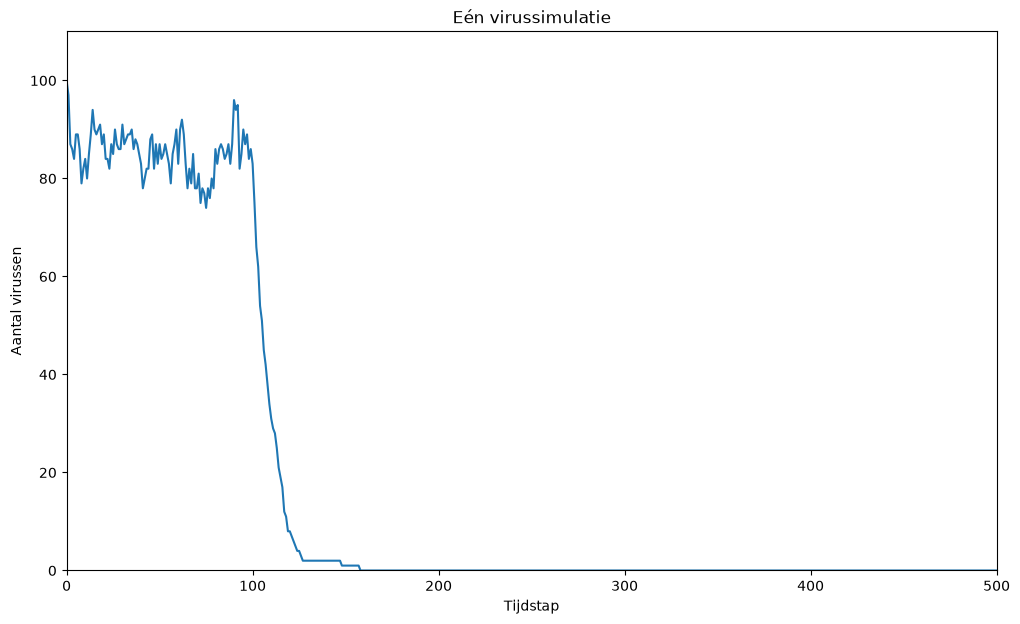

In [23]:
viruses = [generate_virus(4) for _ in range(100)]
result = simulate(viruses, 0.1, 0.1, 0.5, 100, timesteps=500)

fig, ax = plt.subplots(figsize=(12, 7))
ax.plot(range(len(result)), result)
ax.set(title="Eén virussimulatie", xlabel="Tijdstap", ylabel="Aantal virussen")
ax.set_ylim(0, 110)
ax.set_xlim(0, 500)
plt.show()

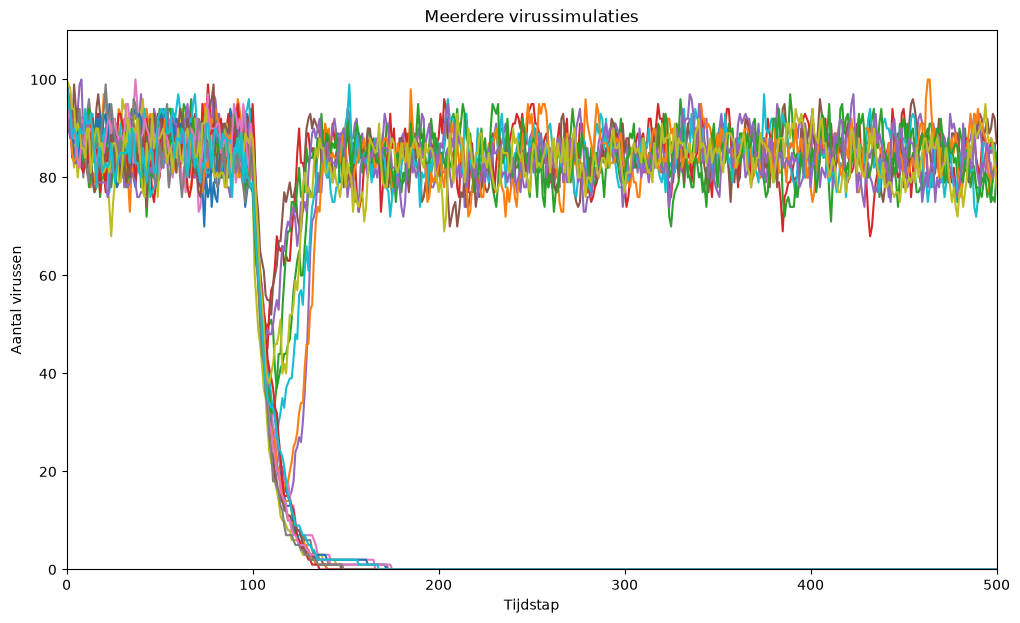

In [24]:
n_simulations = 20
fig, ax = plt.subplots(figsize=(12, 7))

for _ in range(n_simulations):
    viruses = [generate_virus(4) for _ in range(100)]
    result = simulate(viruses, 0.1, 0.1, 0.5, 100, timesteps=500)
    ax.plot(range(len(result)), result)

ax.set(title="Meerdere virussimulaties", xlabel="Tijdstap", ylabel="Aantal virussen")
ax.set_ylim(0, 110)
ax.set_xlim(0, 500)
plt.show()

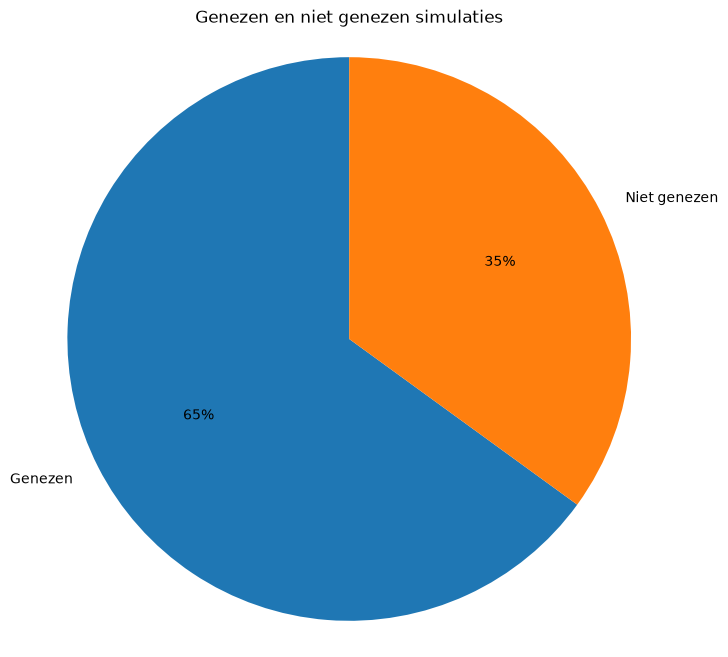

Genezen in 65 van de 100 simulaties.


In [25]:
n_simulations = 100
n_simulations_cured = 0

for _ in range(n_simulations):
    viruses = [generate_virus(4) for _ in range(100)]
    result = simulate(viruses, 0.1, 0.1, 0.5, 100, timesteps=500)

    if result[-1] == 0:
        n_simulations_cured += 1

labels = ["Genezen", "Niet genezen"]
sizes = [n_simulations_cured, n_simulations - n_simulations_cured]

fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(sizes, labels=labels, autopct="%1i%%", startangle=90)
ax.axis("equal")
ax.set_title("Genezen en niet genezen simulaties")
plt.show()

print(f"Genezen in {n_simulations_cured} van de {n_simulations} simulaties.")

In [26]:
import doctest

def _virus_doctests():
    """
    >>> len(generate_virus(4))
    4
    >>> set(generate_virus(100)) <= set("ACGT")
    True

    >>> mutate("") == ""
    True
    >>> len(mutate("ACGT")) == 4 and mutate("ACGT") != "ACGT"
    True

    >>> kill(["A", "C"], 0)
    ['A', 'C']
    >>> kill(["A", "C"], 1)
    []

    >>> reproduce(["A"], 0.5, 0)
    ['A']

    >>> is_resistant("CAAA")
    True
    >>> is_resistant("AACA")
    False

    >>> reproduction_probability(["A", "C"], 0.5, 4)
    0.25
    >>> simulate(["AAAA", "CCCC"], 1, 0, 0, 10, timesteps=2)
    [2, 0, 0]
    """


doctest.run_docstring_examples(_virus_doctests, globals(), verbose=True)

Finding tests in NoName
Trying:
    len(generate_virus(4))
Expecting:
    4
ok
Trying:
    set(generate_virus(100)) <= set("ACGT")
Expecting:
    True
ok
Trying:
    mutate("") == ""
Expecting:
    True
ok
Trying:
    len(mutate("ACGT")) == 4 and mutate("ACGT") != "ACGT"
Expecting:
    True
ok
Trying:
    kill(["A", "C"], 0)
Expecting:
    ['A', 'C']
ok
Trying:
    kill(["A", "C"], 1)
Expecting:
    []
ok
Trying:
    reproduce(["A"], 0.5, 0)
Expecting:
    ['A']
ok
Trying:
    is_resistant("CAAA")
Expecting:
    True
ok
Trying:
    is_resistant("AACA")
Expecting:
    False
ok
Trying:
    reproduction_probability(["A", "C"], 0.5, 4)
Expecting:
    0.25
ok
Trying:
    simulate(["AAAA", "CCCC"], 1, 0, 0, 10, timesteps=2)
Expecting:
    [2, 0, 0]
ok
